In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), '../src'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_id = 0

neurons_max = 5

dims = 2

In [4]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(filename,
 traces,
 states, markers) = read_utils.get_data(path, file_id)

# clear nan values
mask = markers.notna().all(axis=1)

traces = traces[mask]
markers = markers[mask]
states = states[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in
	enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
	return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rate = read_utils.get_sampling_rate(os.path.join(path, filename))
traces = pd.DataFrame(highpass_butter(traces.values, sampling_rate, 1 / 100), columns=traces.columns)
#markers_grad = pd.DataFrame(np.gradient(markers.values, axis=0), columns=markers.columns)

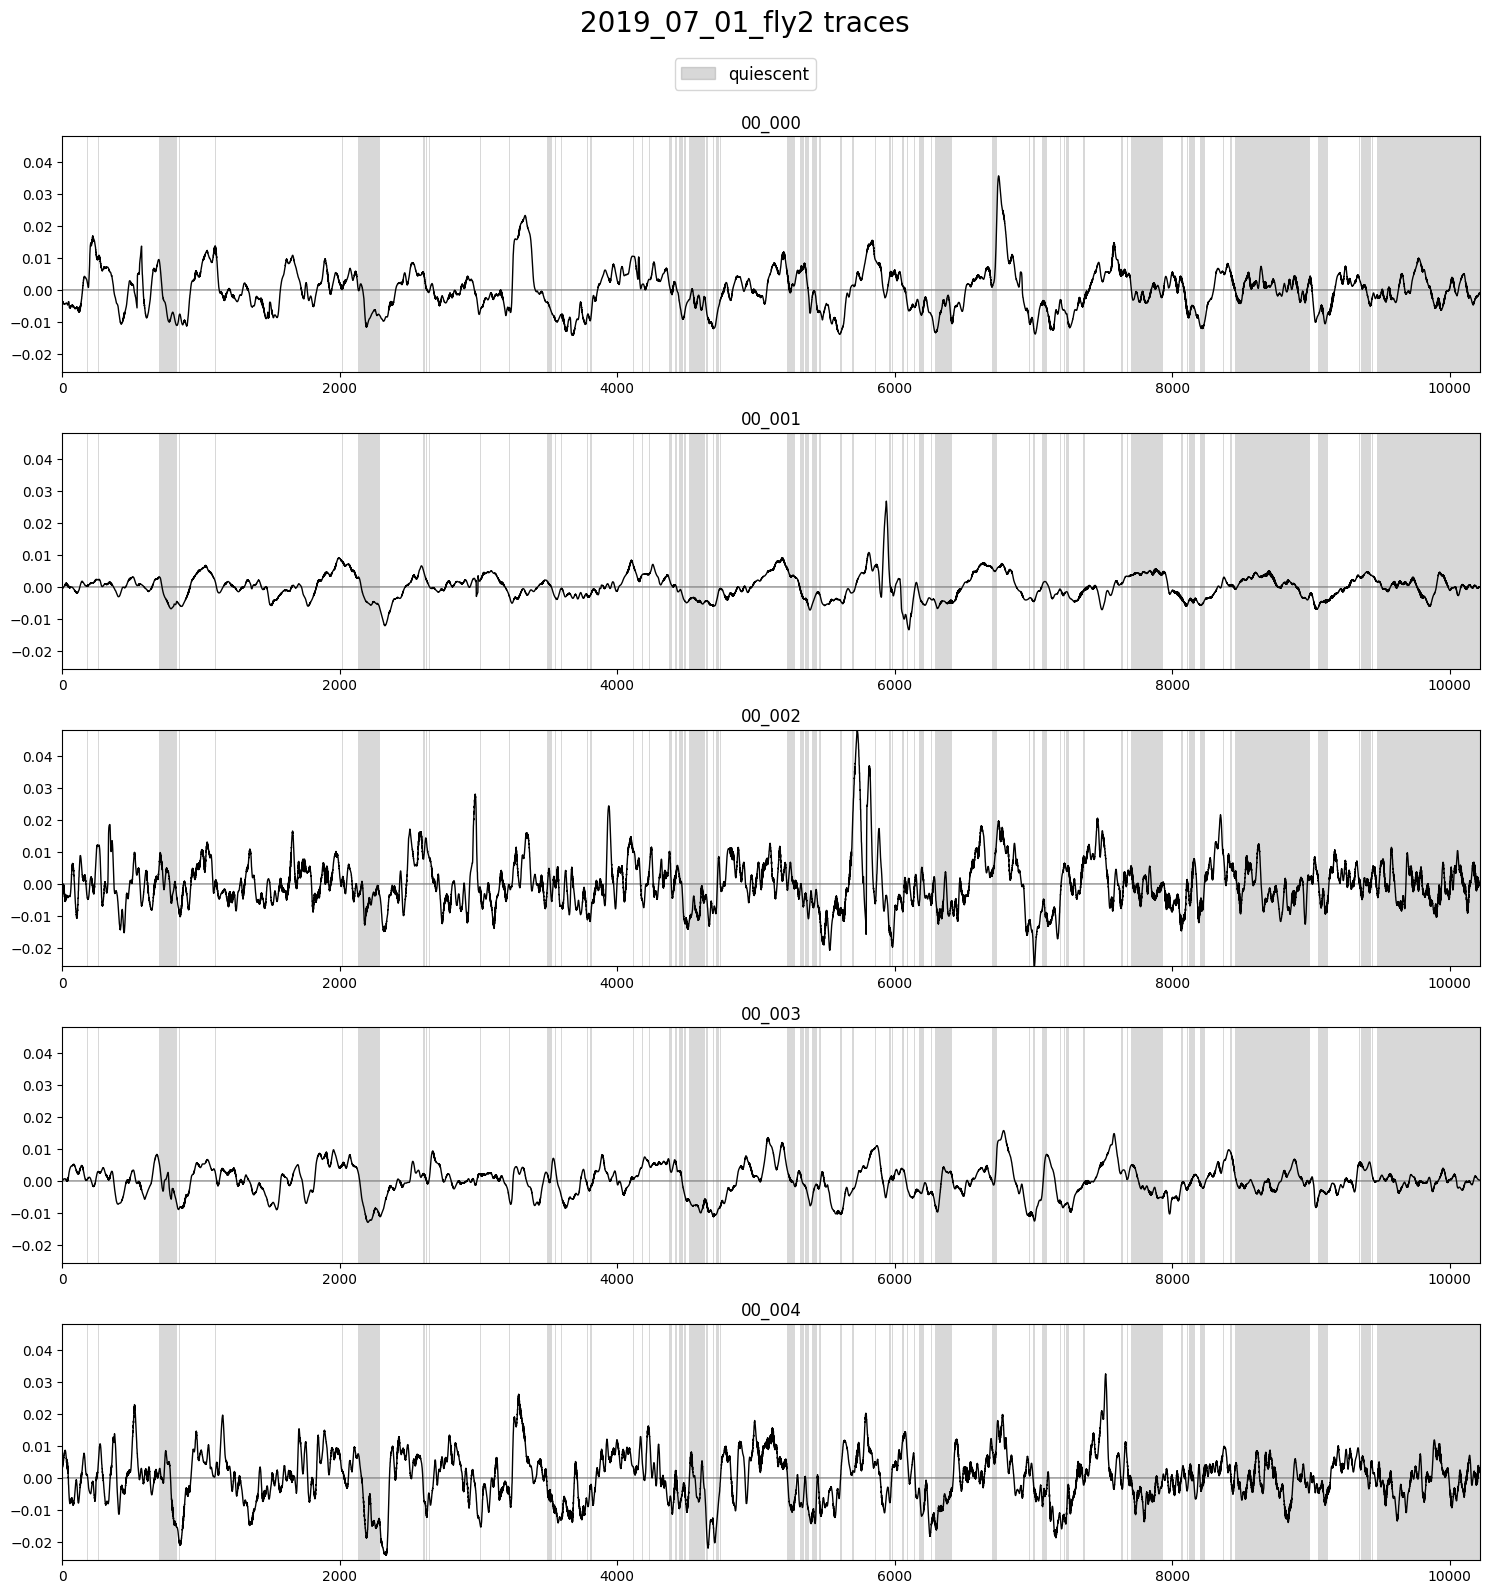

In [5]:
plot_utils.plot_traces(traces.iloc[:, :neurons_max],
					   states[['still']],
					   label='quiescent',
					   title=f'{filename} traces', ylimits=None)

# sklearn PCA

In [6]:
X = traces.values

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca([traces], scale=False,
												 n_pc=dims)

X_l_h_df = modes_manifold[0]
X_l_h = X_l_h_df.values
X_rec_h_df = recos_manifold[0]
X_rec_h = X_rec_h_df.values

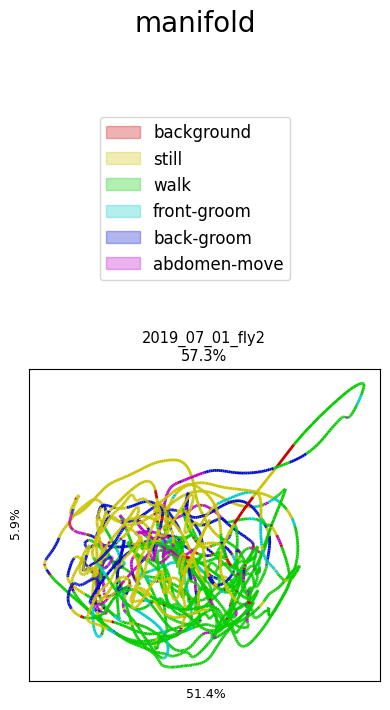

57.3%


In [8]:
# X_l_h_df = pd.DataFrame(data=X_l_h, columns=[f'PC{i}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_h_df],
							  [states],
							  vars_expl_mans, None,
							  title='manifold', top_space=3.5,
							  save_path=None)

In [9]:
# plot_utils.plot_traces([X_l_h_df],
# 					   states[['still']],
# 					   label='quiescent',
# 					   title=f'[{filename}] pca neural modes', ylimits=None)

In [10]:
# X_rec_h_df = pd.DataFrame(data=X_rec_h, columns=traces.columns)
#
# plot_utils.plot_traces([traces.iloc[:, :neurons_max], X_rec_h_df.iloc[:, :neurons_max]],
# 					   states[['still']],
# 					   label='quiescent',
# 					   title=f'[{filename}] pca neural reconstructions', ylimits=None)

# soft PCA

In [11]:
@jax.jit
def orthonormalize_qr(A):
	Q, R = jnp.linalg.qr(A, mode='reduced')
	signs = jnp.sign(jnp.diag(R))  # fix sign ambiguity for a deterministic mapping
	return Q * jnp.where(signs == 0, 1.0, signs)


@jax.jit
def predict(params, N):
	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	N_mean, N_std = prep_n['mean'], prep_n['std']

	U = params['model']['U']

	# U_orth = U
	U_orth = orthonormalize_qr(U)

	N_zs = (N - N_mean) / N_std

	N_man = N_zs @ U_orth

	N_zs_rec = N_man @ U_orth.T
	N_rec = N_zs_rec * N_std + N_mean

	return N_man, N_rec


def loss_fn(params, N):
	N_man, N_rec = predict(params, N)

	# man_loss = jnp.mean(jnp.mean(jnp.abs(N - N_rec) ** 1, axis=0))
	# man_loss = jnp.mean(jnp.mean(N - N_rec ** 2, axis=0))
	man_loss = jnp.mean((N - N_rec) ** 2)

	# N_man_c = N_man - jnp.mean(N_man, axis=0)
	# N_man_c_cov  = (N_man_c.T @ N_man_c) / N_man_c.shape[0]
	# corr_loss = jnp.sum((N_man_c_cov - jnp.diag(jnp.diag(N_man_c_cov))) ** 2)
	corr_loss = jnp.array(0.0)

	return man_loss + corr_loss

loss_and_grads = jax.jit(jax.value_and_grad(loss_fn, has_aux=False))


def update(opt_update, opt_state, params, N):
	loss, grads = loss_and_grads(params, N)
	params_updates, opt_state = opt_update(grads, opt_state, params)
	params_new = optax.apply_updates(params, params_updates)
	return opt_state, params_new, loss

update = jax.jit(update, static_argnums=(0,))

In [12]:
def init_params(N, n_dimensions, seeds, scale=False):
	return {
		'prep': {
			'N': {
				'mean': N.mean(axis=0),
				'std': jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std) if scale else jnp.ones((N.shape[1],)),
			},
		},
		'model': {
			'U': 1E-3 * jax.random.normal(seeds[0], (N.shape[1], n_dimensions)),
		}
	}


def train(N, hyperparams, scale=False):
	max_epochs = hyperparams['max_epochs']
	n_dimensions = hyperparams['dimensions']
	learning_rate = hyperparams['learning_rate']

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)
	params = init_params(N, n_dimensions, seeds, scale)
	# optimizer = optax.adam(learning_rate)
	optimizer = optax.adam(
		learning_rate=optax.cosine_decay_schedule(
			init_value=learning_rate,
			decay_steps=max_epochs,
			alpha=1E-4
		)
	)
	optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
	opt_state = optimizer.init(params)

	losses_train = []
	for epoch in range(max_epochs):
		opt_state, params, loss_train = update(optimizer.update, opt_state, params, N)
		losses_train.append(loss_train)

	return params, losses_train

In [13]:
hyperparameters = {
	'max_epochs': 5000,
	'learning_rate': 1E-0,
	'dimensions': dims
}

# splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces.shape[0]),
# 															   states[['still']].values))
#
# results = list()
# for i in range(len(splits)):
# 	X_train, X_test = X[splits[i][0]], X[splits[i][1]]
# 	params, losses_train = train(X_train, hyperparameters)
# 	X_l_s, X_rec_s = predict(params, X)
# 	results.append((X_l_s, X_rec_s, losses_train))

params, losses_train = train(X, hyperparameters, scale=False)
X_l_s, X_rec_s = predict(params, X)

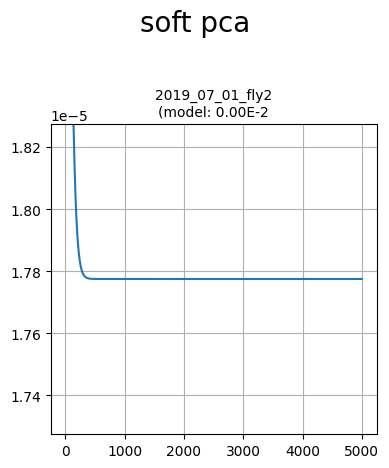

In [14]:
losses = np.array(losses_train)

plot_utils.plot_loss(filename,
					 losses,
					 title='soft pca', ylimits=0.000005, plots_per_row=1)

In [15]:
# splits = 5
# plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
# 						  [pd.DataFrame(results[s][0], columns=[f'PC{i+1}' for i in range(dims)]) for s in range(splits)],
# 						  [states for s in range(splits)],
# 						  None, None,
# 						  title='manifold', plots_per_row=splits, top_space=3.5,
# 						  save_path=None)

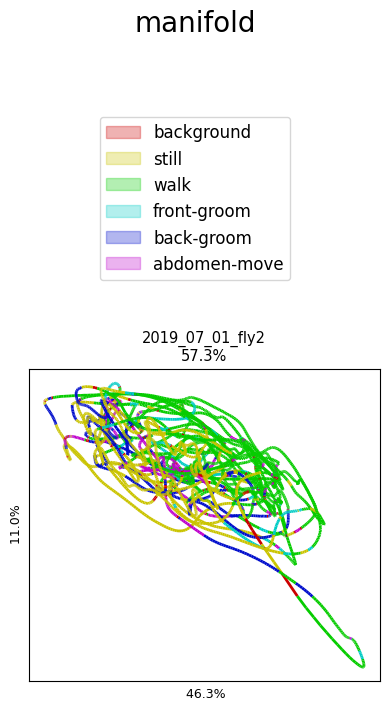

57.3%


In [26]:
X_l_s, vars_expl = train_utils.postprocess_manifold(X_l_s, X, lambda X: X @ orthonormalize_qr(params['model']['U']).T, scale=False, align=False)

X_l_s_df = pd.DataFrame(data=X_l_s, columns=[f'PC{i+1}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_s_df],
							  [states],
							  [vars_expl], None,
							  title='manifold', top_space=3.5,
							  save_path=None)

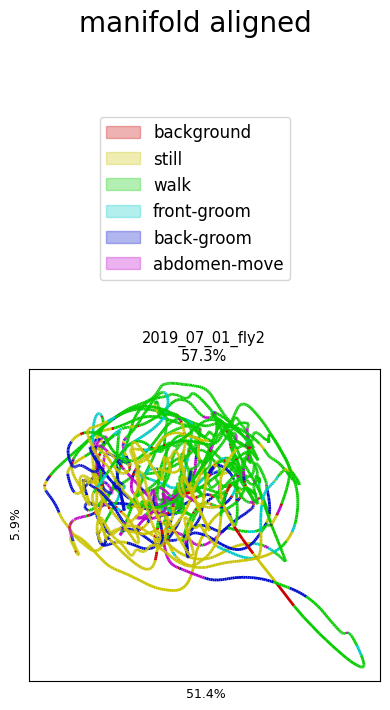

57.3%


In [34]:
X_l_s_p, vars_expl = train_utils.postprocess_manifold(X_l_s, X, lambda X: X @ orthonormalize_qr(params['model']['U']).T, scale=False, align=True)

X_l_s_p_df = pd.DataFrame(data=X_l_s_p, columns=[f'PC{i+1}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_s_p_df],
							  [states],
							  [vars_expl], None,
							  title='manifold aligned', top_space=3.5,
							  save_path=None)

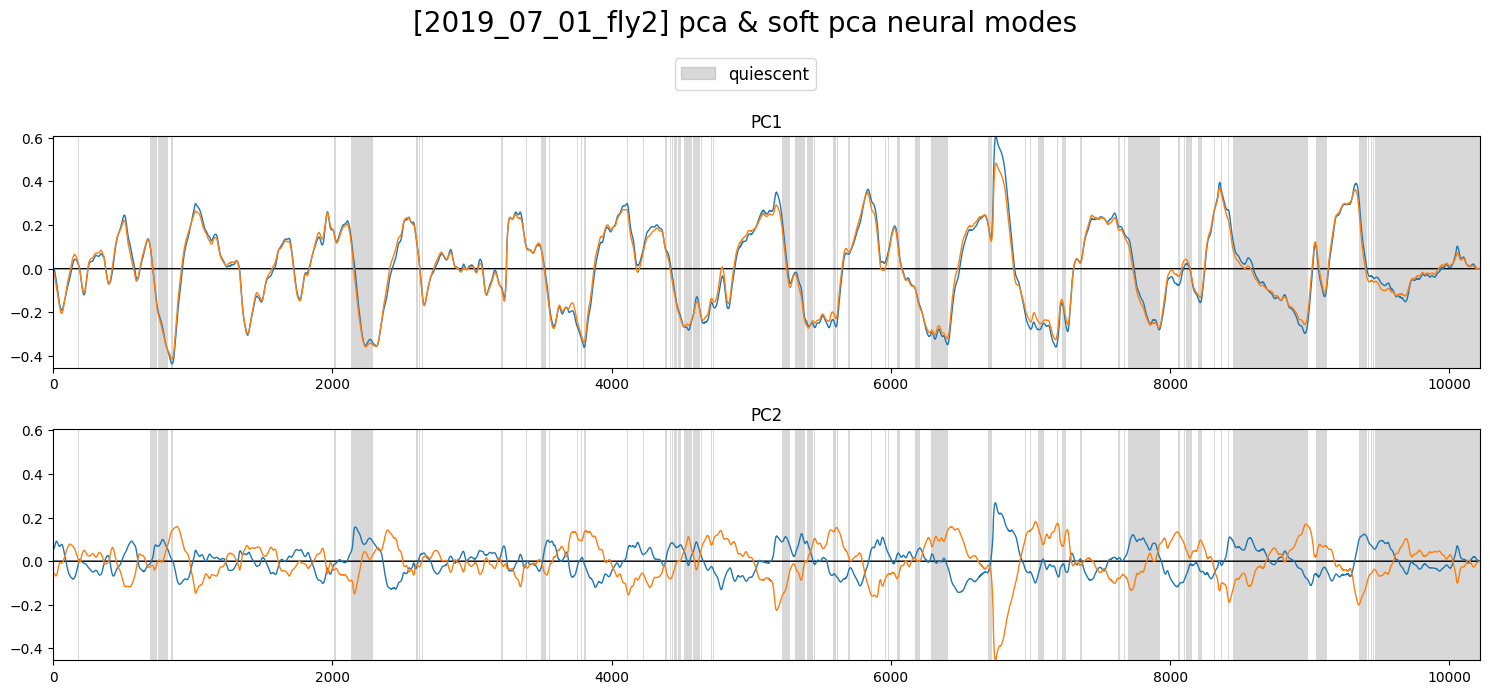

In [29]:
dummy = pd.DataFrame(np.zeros(X_l_h_df.shape), columns=X_l_h_df.columns)

plot_utils.plot_traces([dummy, X_l_h_df, X_l_s_df],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filename}] pca & soft pca neural modes', ylimits=None)

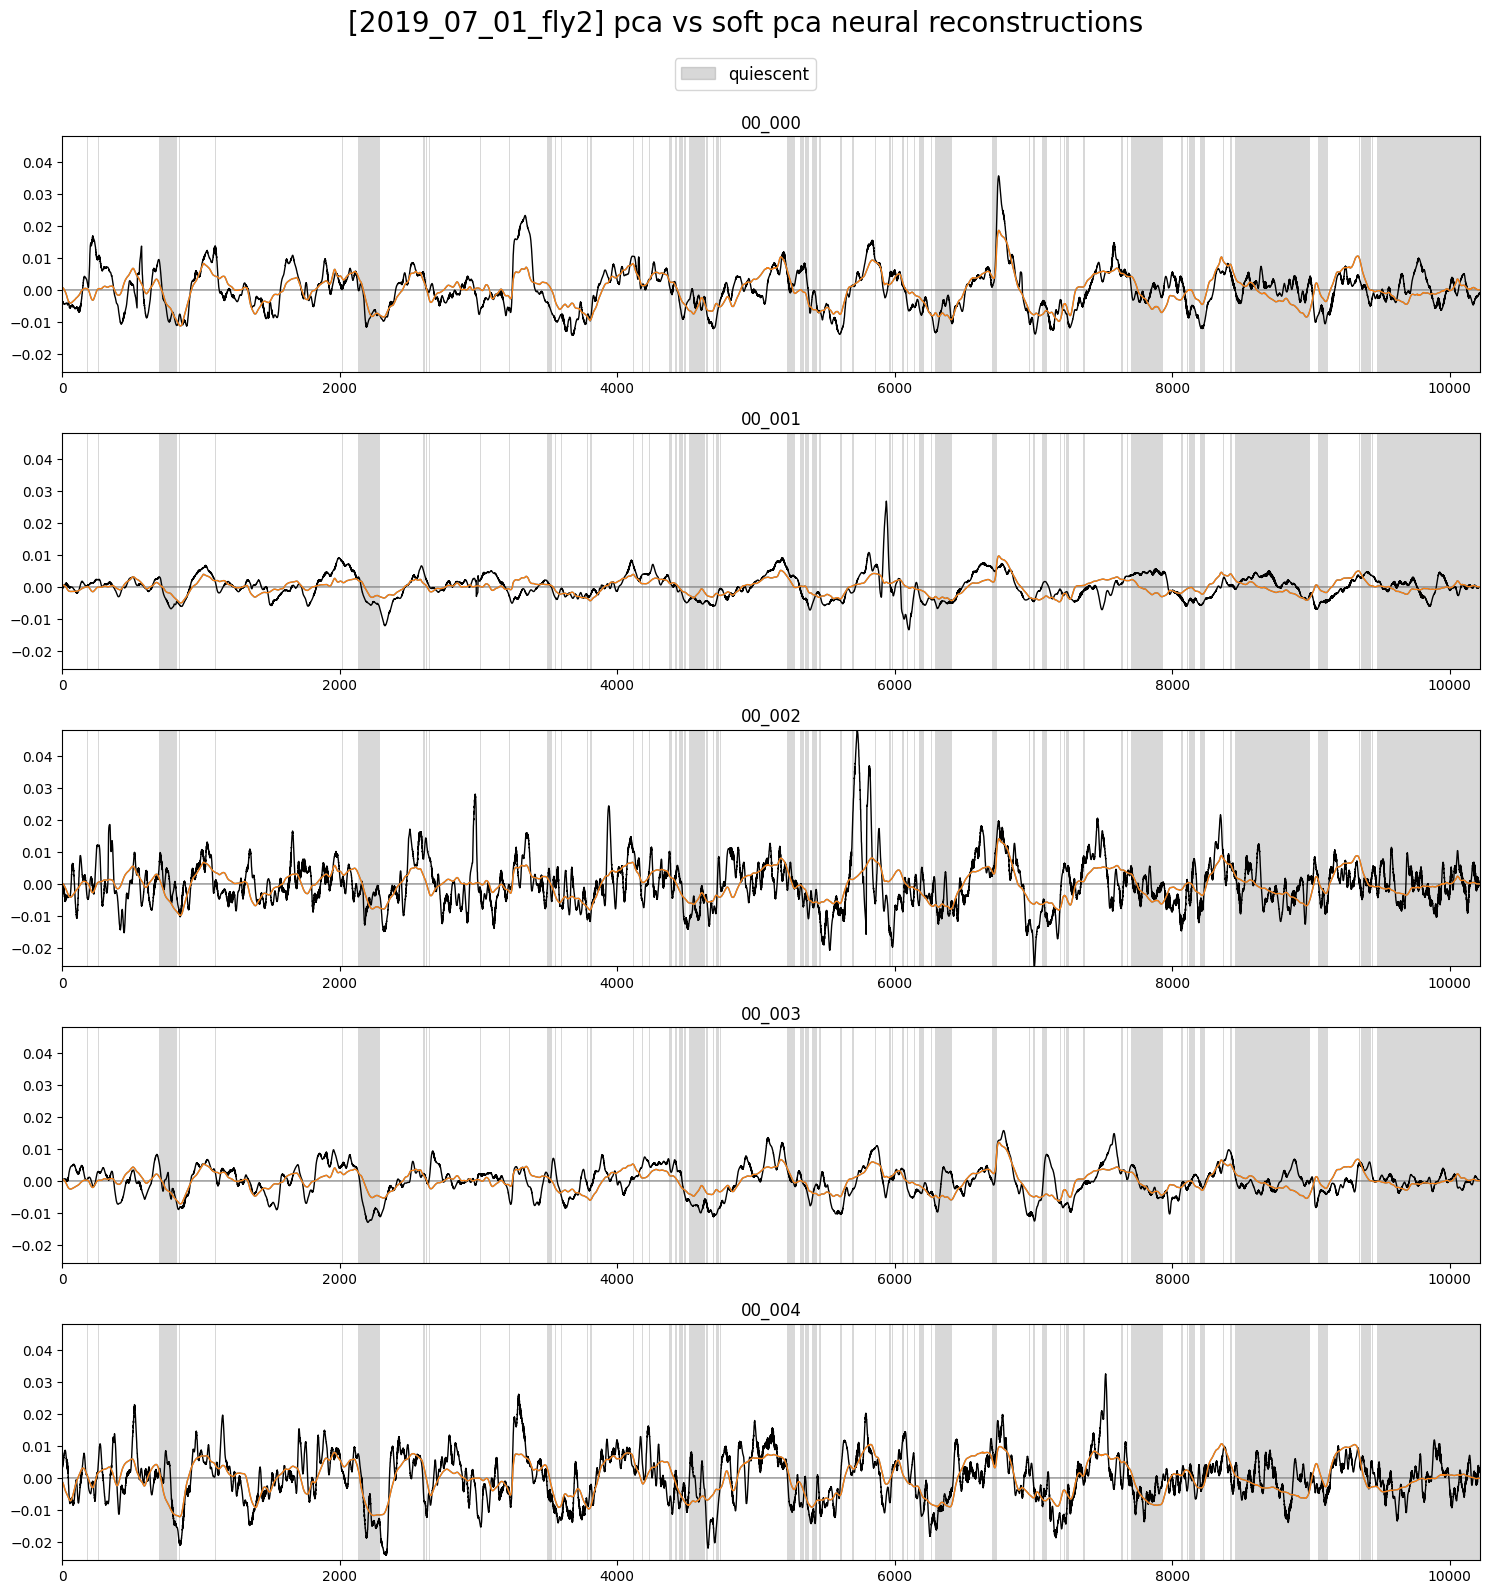

In [30]:
X_rec_s_df = pd.DataFrame(data=X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces.iloc[:, :neurons_max], X_rec_h_df.iloc[:, :neurons_max], X_rec_s_df.iloc[:, :neurons_max]],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filename}] pca vs soft pca neural reconstructions', ylimits=None)

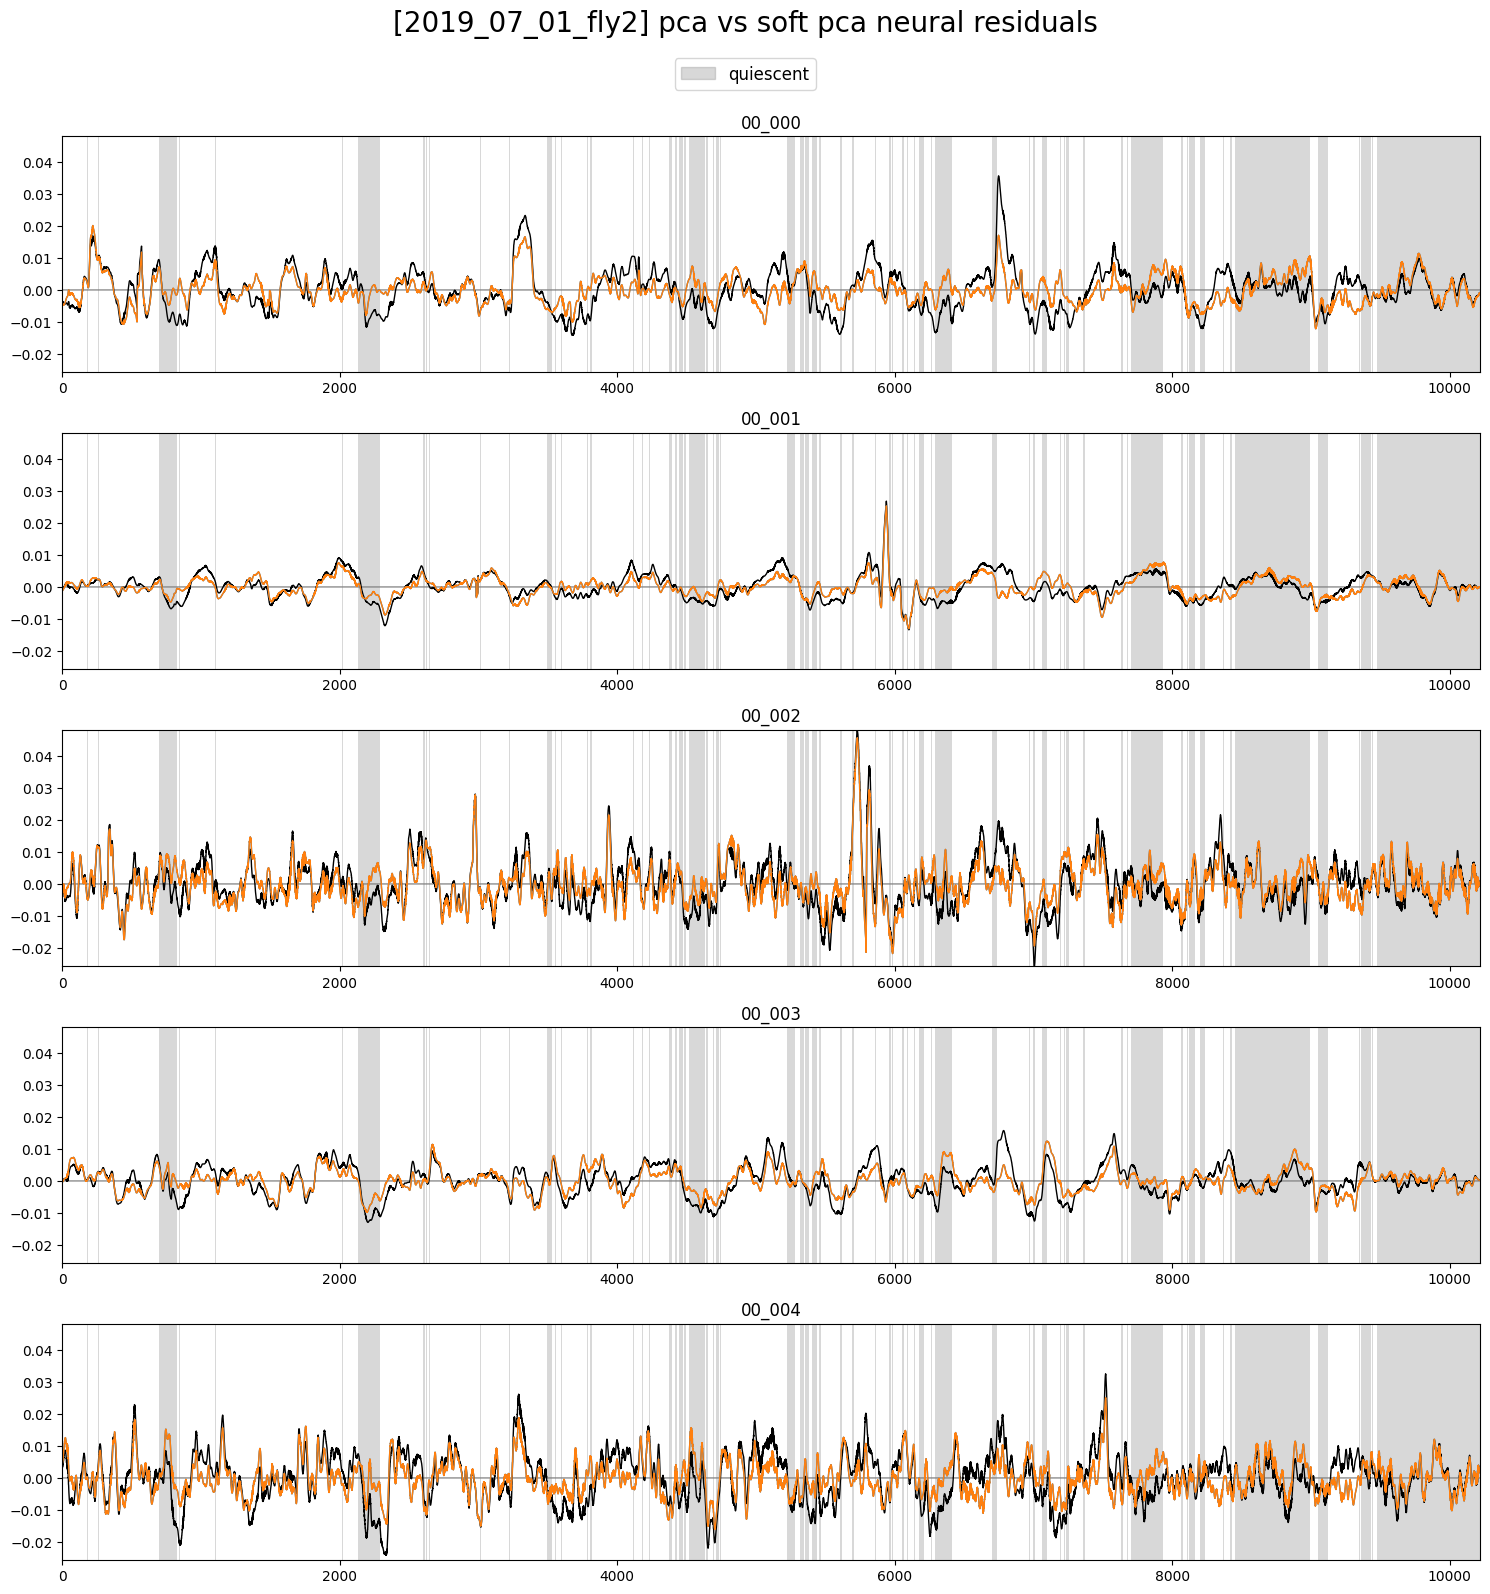

In [31]:
X_res_h_df = pd.DataFrame(data=X - X_rec_h, columns=traces.columns)
X_res_s_df = pd.DataFrame(data=X - X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces.iloc[:, :neurons_max], X_res_h_df.iloc[:, :neurons_max], X_res_s_df.iloc[:, :neurons_max]],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filename}] pca vs soft pca neural residuals', ylimits=None)

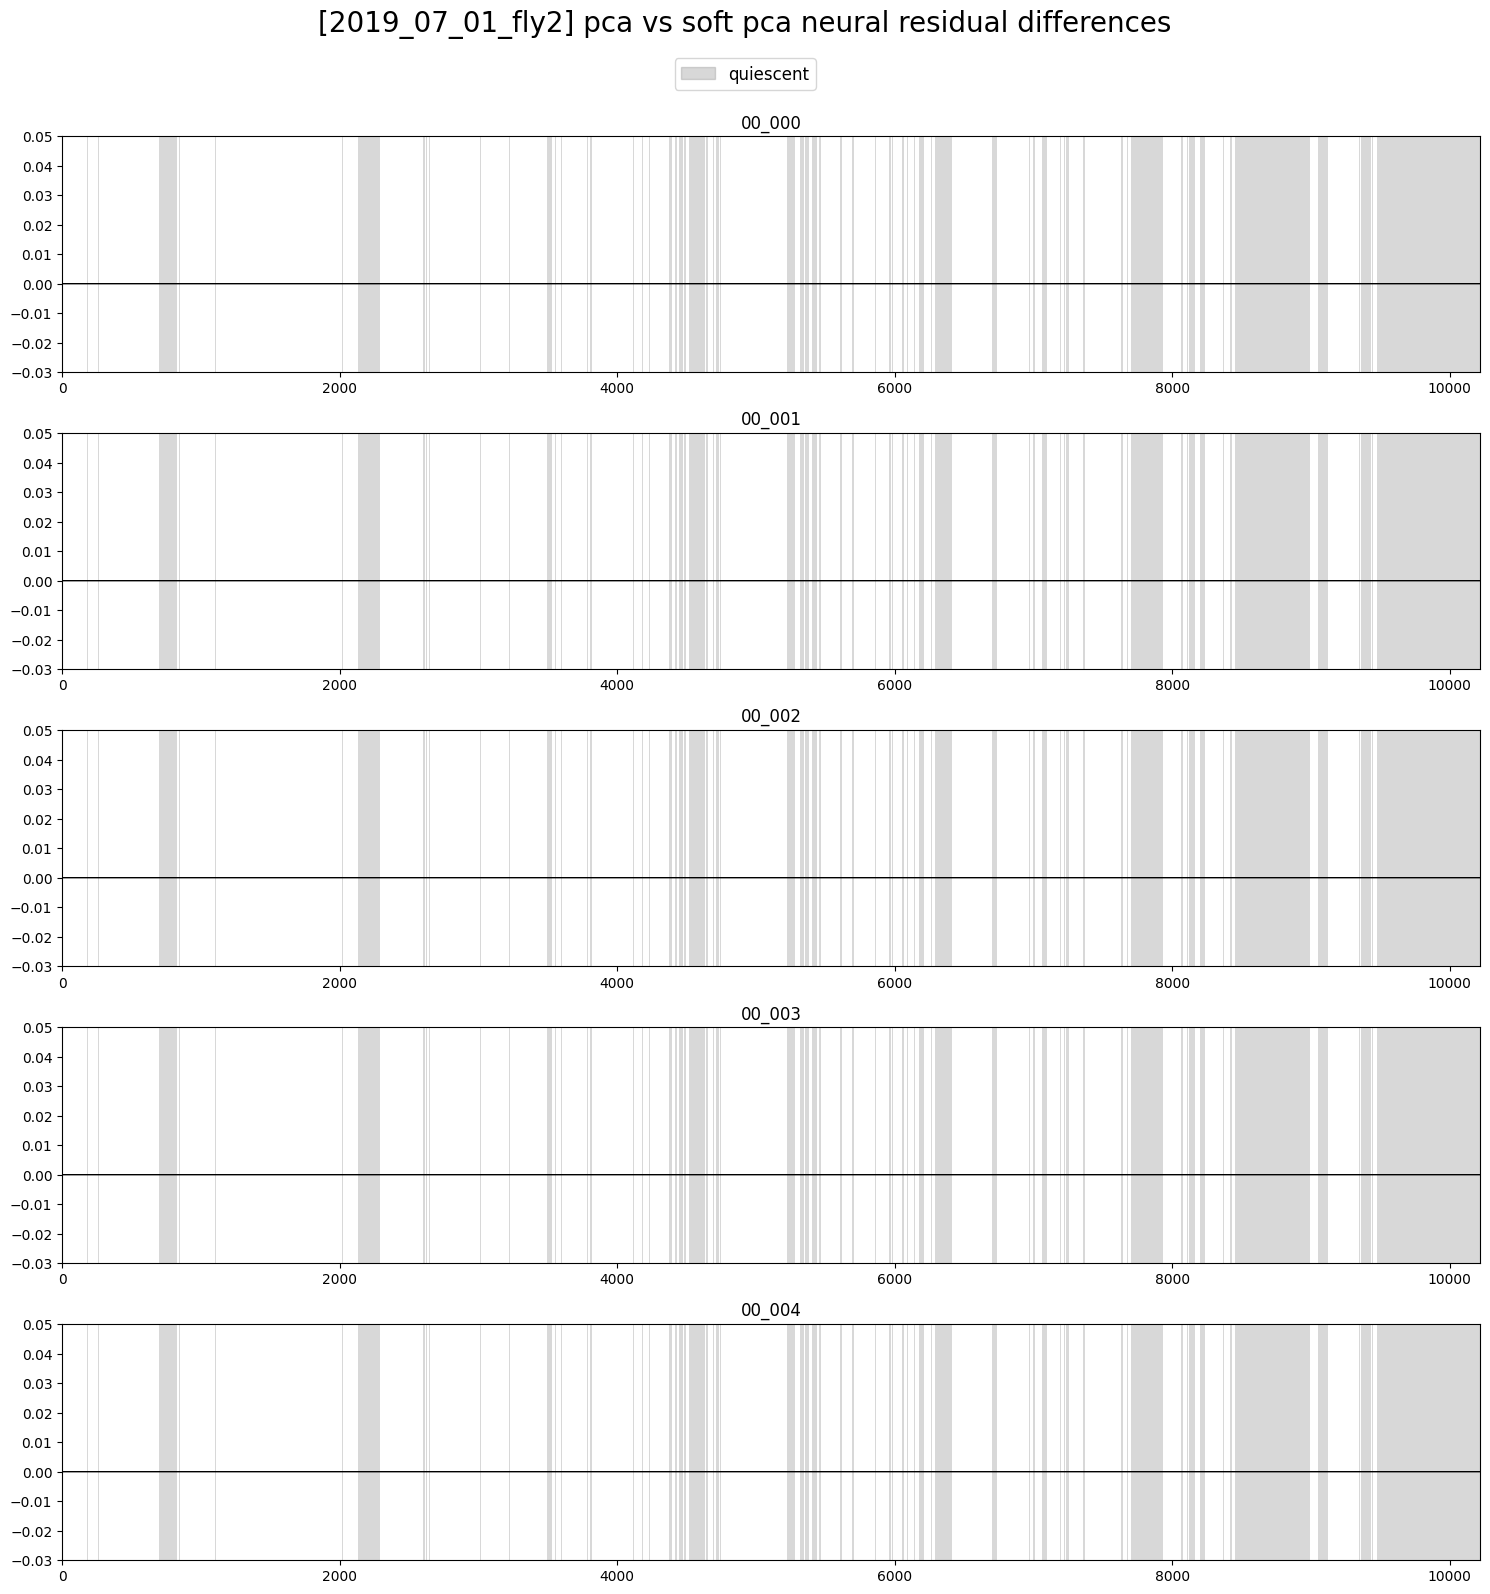

In [32]:
plot_utils.plot_traces([X_res_h_df.iloc[:, :neurons_max] - X_res_s_df.iloc[:, :neurons_max]],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filename}] pca vs soft pca neural residual differences', ylimits=(-0.03, 0.05))

[[ 0.0300696  -0.00931848]
 [-0.00931848  0.00713639]]
[[ 1.0000005e+00 -2.3861977e-08]
 [-2.3861977e-08  9.9999988e-01]]


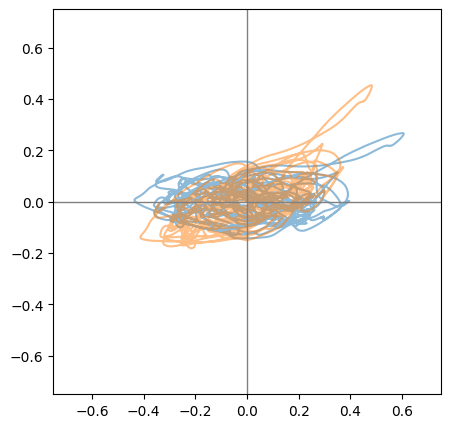

In [33]:
plt.figure(figsize=(5, 5))
plt.plot(X_l_h[:, 0], X_l_h[:, 1], alpha=0.5)
plt.plot(X_l_s[:, 0], X_l_s[:, 1] * -1, alpha=0.5)
plt.axhline(0, color='gray', linewidth=1)
plt.axvline(0, color='gray', linewidth=1)
plt.xlim(-0.75, 0.75)
plt.ylim(-0.75, 0.75)

print((X_l_s.T @ X_l_s) / X_l_s.shape[0])
np.linalg.eigvals(X_l_s.T @ X_l_s)

encoder = orthonormalize_qr(params['model']['U'])
# encoder = params['model']['U']
print(encoder.T @ encoder)